# SPUS vs S&P500

### This notebook aims at systematically studying the behaviour of both markets

# Import

In [1]:
import sys
sys.path.append('../src')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.gridspec as gridspec
import seaborn as sns
from scipy import stats

from data import download_prices, compute_returns
from universe import get_universe, universe_diff, get_full_universe
from metrics import sharpe_ratio, annualised_return, max_drawdown, summary
from volatility import (
    rolling_vol, ewma_vol,
    fit_garch_universe, garch_conditional_vol,
    compare_universes
)
from signals import cross_section_zscore, momentum, short_term_reversal, volatility_signal

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.dpi'] = 120
print('Imports OK')

Imports OK


In [2]:
sp500_tickers = get_full_universe('sp500')
spus_tickers  = get_full_universe('spus')

all_tickers  = list(set(sp500_tickers + spus_tickers))
prices_all   = download_prices(all_tickers, start='2015-01-01')

sp500_cols   = [t for t in sp500_tickers if t in prices_all.columns]
spus_cols    = [t for t in spus_tickers  if t in prices_all.columns]

prices_sp500 = prices_all[sp500_cols]
prices_spus  = prices_all[spus_cols]
returns_sp500 = compute_returns(prices_all[sp500_cols])
returns_spus  = compute_returns(prices_all[spus_cols])

print(f'SP500: {returns_sp500.shape[1]} stocks | SPUS: {returns_spus.shape[1]} stocks')

Fetched 503 S&P 500 tickers from Wikipedia
Fetched 503 S&P 500 tickers from Wikipedia
SPUS: 422 stocks (excluded 81)
Loading from cache: prices_2015-01-01_today.csv
SP500: 470 stocks | SPUS: 392 stocks


In [5]:
columns_not_in_both = set(returns_sp500.columns) - set(returns_spus.columns)
prices_diff = prices_sp500[list(columns_not_in_both)]
returns_diff = returns_sp500[list(columns_not_in_both)]

print(f"Diff universe: {returns_diff.shape[1]} stocks")

Diff universe: 78 stocks


In [6]:
columns_not_in_both = np.array(list(columns_not_in_both))

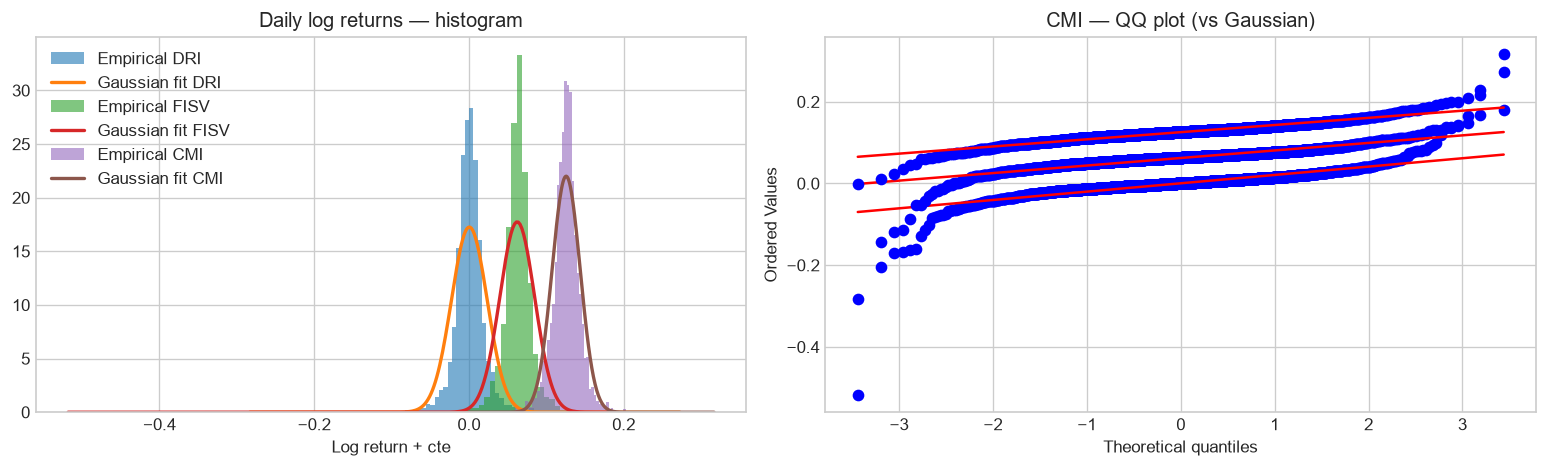

In [7]:
# Pick a representative stock
ticker_list = np.random.choice(list(prices_spus.columns), size=3, replace=False)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for i in range(len(ticker_list)):
    ticker = ticker_list[i]
    r = returns_spus[ticker].dropna() + i/16
    # Histogram vs Gaussian
    ax = axes[0]
    r.hist(bins=100, density=True, alpha=0.6, ax=ax, label=f'Empirical {ticker}')
    x = np.linspace(r.min(), r.max(), 300)
    ax.plot(x, stats.norm.pdf(x, r.mean(), r.std()), lw=2, label=f'Gaussian fit {ticker}')
    
    
    
    # QQ plot
    ax = axes[1]
    stats.probplot(r, dist='norm', plot=ax)
axes[0].set_title(f'Daily log returns — histogram')
axes[1].set_title(f'{ticker} — QQ plot (vs Gaussian)')
axes[0].set_xlabel('Log return + cte'); axes[0].legend() 
plt.tight_layout()
plt.show()
    
    #print(f'Skewness : {r.skew():.3f}  (Gaussian = 0)')
    #print(f'Kurtosis : {r.kurtosis():.3f}  (Gaussian = 0, excess)')
    #print(f'Fat tails confirmed: kurtosis >> 0')

In [ ]:
sharpe_sp500 = []
ann_return_sp500 = []
mdd_sp500 = []
for s in returns_sp500.columns:
    print(s)
    stats = summary(returns_sp500[s])
    sharpe_sp500.append(float(stats['Sharpe (gross)']))
    ann_return_sp500.append(float(stats['Annualised Return'][:-1]))
    mdd_sp500.append(float(stats['Max Drawdown'][:-1]))

In [ ]:
sharpe_spus = []
ann_return_spus = []
mdd_spus = []
for s in returns_spus.columns:
    print(s)
    stats = summary(returns_sp500[s])
    sharpe_spus.append(float(stats['Sharpe (gross)']))
    ann_return_spus.append(float(stats['Annualised Return'][:-1]))
    mdd_spus.append(float(stats['Max Drawdown'][:-1]))

In [ ]:
sharpe_diff = []
ann_return_diff = []
mdd_diff = []
for s in columns_not_in_both:
    print(s)
    stats = summary(returns_diff[s])
    sharpe_diff.append(float(stats['Sharpe (gross)']))
    ann_return_diff.append(float(stats['Annualised Return'][:-1]))
    mdd_diff.append(float(stats['Max Drawdown'][:-1]))

In [11]:
print('S&P500 mean +/- std')
print(f'Sharpe : {np.mean(sharpe_sp500):.2f} +/- {np.std(sharpe_sp500):.2f}')
print(f'Annualised Return : {np.mean(ann_return_sp500):.2f}% +/- {np.std(ann_return_sp500):.2f}%')
print(f'Max Drawdown : {np.mean(mdd_sp500):.2f}% +/- {np.std(mdd_sp500):.2f}%')
print('--------------------')
print('SPUS mean +/- std')
print(f'Sharpe : {np.mean(sharpe_spus):.2f} +/- {np.std(sharpe_spus):.2f}')
print(f'Annualised Return : {np.mean(ann_return_spus):.2f}% +/- {np.std(ann_return_spus):.2f}%')
print(f'Max Drawdown : {np.mean(mdd_spus):.2f}% +/- {np.std(mdd_spus):.2f}%')
print('--------------------')
print('Diff mean +/- std')
print(f'Sharpe : {np.mean(sharpe_diff):.2f} +/- {np.std(sharpe_diff):.2f}')
print(f'Annualised Return : {np.mean(ann_return_diff):.2f}% +/- {np.std(ann_return_diff):.2f}%')
print(f'Max Drawdown : {np.mean(mdd_diff):.2f}% +/- {np.std(mdd_diff):.2f}%')


S&P500 mean +/- std
Sharpe : 0.35 +/- 0.23
Annualised Return : 5.81% +/- 8.97%
Max Drawdown : -59.28% +/- 15.99%
--------------------
SPUS mean +/- std
Sharpe : 0.36 +/- 0.24
Annualised Return : 6.09% +/- 9.31%
Max Drawdown : -59.24% +/- 16.64%
--------------------
Diff mean +/- std
Sharpe : 0.31 +/- 0.20
Annualised Return : 4.39% +/- 6.84%
Max Drawdown : -59.49% +/- 12.20%


In [12]:
from scipy import stats as scipy_stats

t_stat, p_val = scipy_stats.ttest_ind(ann_return_spus, ann_return_sp500)
print(f"SPUS vs S&P500 p-value: {p_val:.4f}")
t_stat, p_val = scipy_stats.ttest_ind(ann_return_spus, ann_return_diff)
print(f"SPUS vs Diff p-value: {p_val:.4f}")
t_stat, p_val = scipy_stats.ttest_ind(ann_return_sp500, ann_return_diff)
print(f"SP500 vs Diff p-value: {p_val:.4f}")

SPUS vs S&P500 p-value: 0.6528
SPUS vs Diff p-value: 0.1281
SP500 vs Diff p-value: 0.1852


### Information coefficient (IC)
<u>Spearman correlation : </u> does the ordering of the signal match the ordering of the returns after 21 days? Measure correlations and assign a score (IC). If IC = 1, perfect ordering. If IC = 0, disordered completely. Generally, a mean IC of 0.01-0.04 is a good indication that the signal is exploitable because markets are not that predictable.  
<u> Pearson correlation : </u> is there a linear relationship between these numbers (stocks with higher singal score returned proportionally more)? 


In [13]:
from scipy import stats as scipy_stats
def information_coefficient(signal, returns, horizon=21, method='spearman'):
    forward_ret = returns.rolling(horizon).sum().shift(-horizon)
    ics = []

    for date in signal.index.intersection(forward_ret.index):
        s = signal.loc[date].dropna()
        f = forward_ret.loc[date].dropna()
        common = s.index.intersection(f.index)
        if len(common) < 20:
            continue

        if method == 'spearman':
            ic, _ = scipy_stats.spearmanr(s[common], f[common])
        else:
            ic, _ = scipy_stats.pearsonr(s[common], f[common])

        ics.append({'date': date, 'IC': ic})

    # Handle empty case
    if not ics:
        return pd.Series(dtype=float, name='IC')

    return pd.DataFrame(ics).set_index('date')['IC'].dropna()

In [14]:
def ic_summary(ic: pd.Series, label: str = "") -> dict:
    """
    Print and return IC summary statistics.
    ICIR = IC / std(IC) — the signal's own Sharpe ratio.
    A signal with ICIR > 0.5 is considered tradeable.
    """
    mean_ic = ic.mean()
    std_ic  = ic.std()
    icir    = mean_ic / std_ic if std_ic > 0 else 0
    pct_pos = (ic > 0).mean() * 100
    t_stat  = mean_ic / (std_ic / np.sqrt(len(ic)))
    p_val   = 2 * (1 - scipy_stats.t.cdf(abs(t_stat), df=len(ic)-1))

    tag = f"[{label}] " if label else ""
    print(f"{tag}Mean IC : {mean_ic:.6f}")
    print(f"{tag}Std IC  : {std_ic:.6f}")
    print(f"{tag}ICIR    : {icir:.6f}")
    print(f"{tag}% positive: {pct_pos:.1f}%")
    print(f"{tag}t-stat  : {t_stat:.2f}  p-value: {p_val:.6f}")

    return dict(mean_ic=mean_ic, std_ic=std_ic, icir=icir,
                pct_pos=pct_pos, t_stat=t_stat, p_val=p_val)


In [15]:
mom_sp500 = momentum(returns_sp500)
mom_spus  = momentum(returns_spus)
mom_diff = momentum(returns_diff)

vol_sp500 = volatility_signal(returns_sp500)
vol_spus  = volatility_signal(returns_spus)
vol_diff  = volatility_signal(returns_diff)

rev_sp500 = short_term_reversal(returns_sp500)
rev_spus  = short_term_reversal(returns_spus)
rev_diff  = short_term_reversal(returns_diff)

## Spearman

In [16]:
ic_mom_sp500 = information_coefficient(mom_sp500, returns_sp500, method='spearman')
ic_mom_spus  = information_coefficient(mom_spus,  returns_spus, method='spearman')
ic_mom_diff  = information_coefficient(mom_diff,  returns_diff, method='spearman')

ic_vol_sp500 = information_coefficient(vol_sp500, returns_sp500, method='spearman')
ic_vol_spus  = information_coefficient(vol_spus,  returns_spus, method='spearman')
ic_vol_diff  = information_coefficient(vol_diff,  returns_diff, method='spearman')

ic_rev_sp500 = information_coefficient(rev_sp500, returns_sp500, method='spearman')
ic_rev_spus  = information_coefficient(rev_spus,  returns_spus, method='spearman')
ic_rev_diff  = information_coefficient(rev_diff,  returns_diff, method='spearman')

In [17]:
signals = {
    'Momentum':  (ic_mom_sp500, ic_mom_spus, ic_mom_diff),
    'Volatility': (ic_vol_sp500, ic_vol_spus, ic_vol_diff),
    'Reversal':  (ic_rev_sp500, ic_rev_spus, ic_rev_diff),
}

print("\n" + "="*60)
for sig_name, (ic_s, ic_u, ic_t) in signals.items():
    print(f"\n{sig_name}")
    print("-"*40)
    ic_summary(ic_s, label="SP500")
    print()
    ic_summary(ic_u, label="SPUS")
    print()
    ic_summary(ic_t, label="Diff")
print("="*60)



Momentum
----------------------------------------
[SP500] Mean IC : 0.004176
[SP500] Std IC  : 0.210256
[SP500] ICIR    : 0.019861
[SP500] % positive: 55.2%
[SP500] t-stat  : 0.91  p-value: 0.364352

[SPUS] Mean IC : 0.004764
[SPUS] Std IC  : 0.204404
[SPUS] ICIR    : 0.023305
[SPUS] % positive: 54.3%
[SPUS] t-stat  : 1.06  p-value: 0.287153

[Diff] Mean IC : -0.003208
[Diff] Std IC  : 0.293170
[Diff] ICIR    : -0.010943
[Diff] % positive: 48.8%
[Diff] t-stat  : -0.50  p-value: 0.617171

Volatility
----------------------------------------
[SP500] Mean IC : -0.034412
[SP500] Std IC  : 0.217603
[SP500] ICIR    : -0.158140
[SP500] % positive: 44.9%
[SP500] t-stat  : -7.65  p-value: 0.000000

[SPUS] Mean IC : -0.034416
[SPUS] Std IC  : 0.215358
[SPUS] ICIR    : -0.159810
[SPUS] % positive: 46.1%
[SPUS] t-stat  : -7.73  p-value: 0.000000

[Diff] Mean IC : -0.026550
[Diff] Std IC  : 0.294920
[Diff] ICIR    : -0.090025
[Diff] % positive: 49.5%
[Diff] t-stat  : -4.35  p-value: 0.000014

Reve

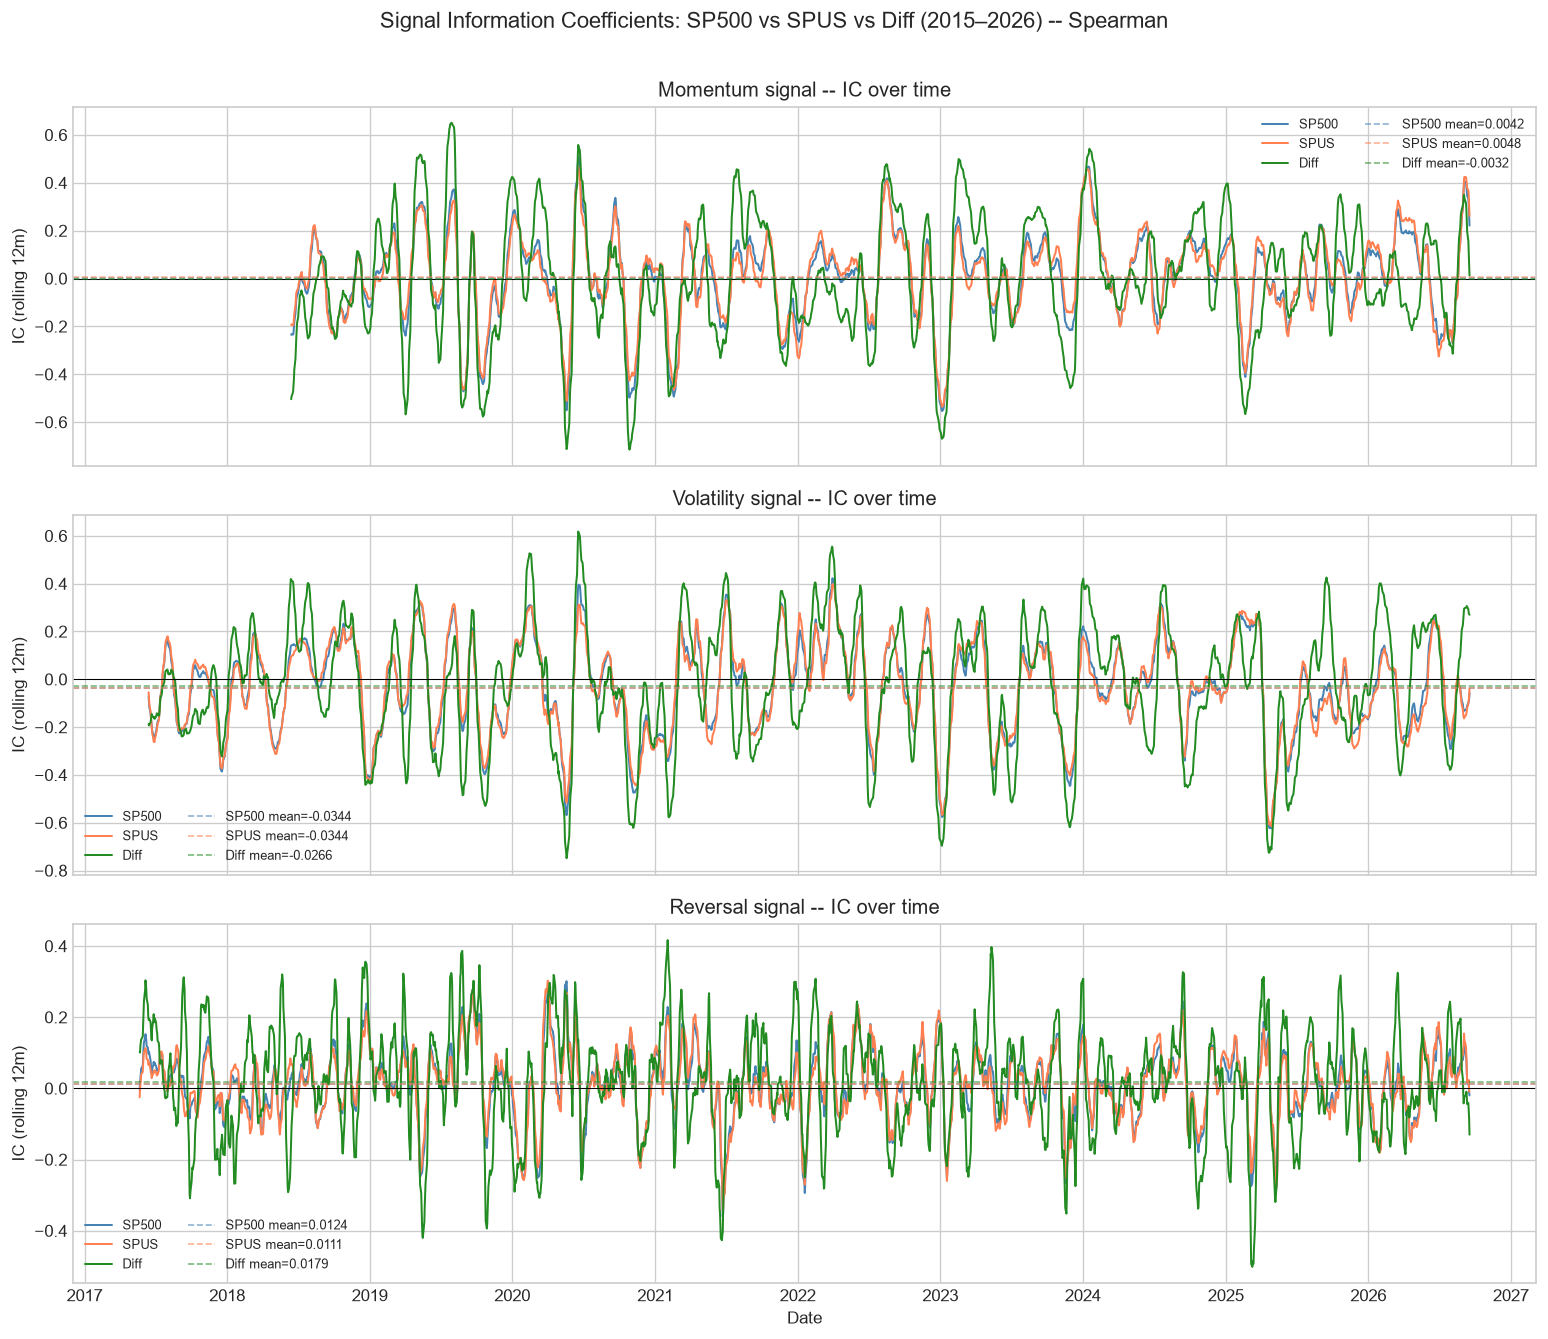

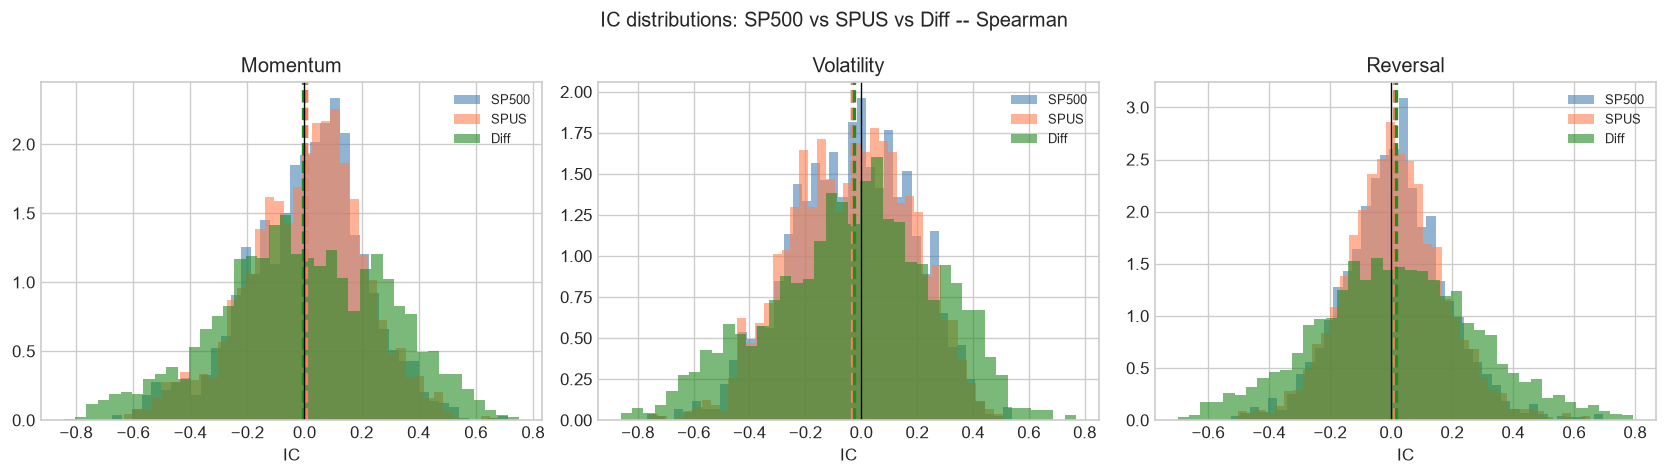

In [18]:

# ── Plot: rolling IC over time ────────────────────────────────────────────────

fig, axes = plt.subplots(3, 1, figsize=(13, 11), sharex=True)
window = 12  # 12-month rolling mean

for ax, sig_name, (ic_s, ic_u, ic_t) in zip(axes, signals.keys(), signals.values()):
    # Align series
    ic_s_roll = ic_s.rolling(window).mean()
    ic_u_roll = ic_u.rolling(window).mean()
    ic_t_roll = ic_t.rolling(window).mean()

    ax.plot(ic_s_roll, color='steelblue', lw=1.2, label='SP500')
    ax.plot(ic_u_roll, color='coral',     lw=1.2, label='SPUS')
    ax.plot(ic_t_roll, color='forestgreen',     lw=1.2, label='Diff')
    ax.axhline(0,              color='black', lw=0.6)
    ax.axhline(ic_s.mean(),   color='steelblue', ls='--', lw=1, alpha=0.6,
               label=f'SP500 mean={ic_s.mean():.4f}')
    ax.axhline(ic_u.mean(),   color='coral',     ls='--', lw=1, alpha=0.6,
               label=f'SPUS mean={ic_u.mean():.4f}')
    ax.axhline(ic_t.mean(),   color='forestgreen',     ls='--', lw=1, alpha=0.6,
               label=f'Diff mean={ic_t.mean():.4f}')

    # Shade periods where IC is negative (signal not working)
    #combined = ic_s_roll.reindex(ic_u_roll.index.union(ic_s_roll.index))
    #ax.fill_between(ic_s_roll.index, ic_s_roll, 0,
    #                where=ic_s_roll < 0,
    #                alpha=0.15, color='red', label='SP500 IC < 0')

    ax.set_ylabel('IC (rolling 12m)')
    ax.set_title(f'{sig_name} signal -- IC over time')
    ax.legend(fontsize=8, ncol=2)
    #ax.set_ylim(-0.15, 0.15)

axes[-1].set_xlabel('Date')
plt.suptitle('Signal Information Coefficients: SP500 vs SPUS vs Diff (2015–2026) -- Spearman',
             y=1.01, fontsize=13)
plt.tight_layout()
plt.show()


# ── IC distribution comparison ────────────────────────────────────────────────

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, sig_name, (ic_s, ic_u, ic_t) in zip(axes, signals.keys(), signals.values()):
    ax.hist(ic_s, bins=40, alpha=0.6, color='steelblue',
            density=True, label='SP500')
    ax.hist(ic_u, bins=40, alpha=0.6, color='coral',
            density=True, label='SPUS')
    ax.hist(ic_t, bins=40, alpha=0.6, color='forestgreen',
            density=True, label='Diff')
    ax.axvline(ic_s.mean(), color='steelblue', ls='--', lw=2)
    ax.axvline(ic_u.mean(), color='coral',     ls='--', lw=2)
    ax.axvline(ic_t.mean(), color='forestgreen',     ls='--', lw=2)
    ax.axvline(0, color='black', lw=0.8)
    ax.set_title(f'{sig_name}')
    ax.set_xlabel('IC')
    ax.legend(fontsize=8)

plt.suptitle('IC distributions: SP500 vs SPUS vs Diff -- Spearman', fontsize=12)
plt.tight_layout()
plt.show()

In [19]:
for sig_name, (ic_s, ic_u, ic_t) in zip(
    ['Momentum', 'Volatility', 'Reversal'],
    [(ic_mom_sp500, ic_mom_spus, ic_mom_diff),
     (ic_vol_sp500, ic_vol_spus, ic_vol_diff),
     (ic_rev_sp500, ic_rev_spus, ic_rev_diff)]
):
    common = ic_s.index.intersection(ic_u.index)
    t, p = scipy_stats.ttest_ind(ic_s[common], ic_u[common])
    print(f"{sig_name}: SP500 vs SPUS IC p-value = {p:.4f}")
    print()
    common = ic_u.index.intersection(ic_t.index)
    t, p = scipy_stats.ttest_ind(ic_u[common], ic_t[common])
    print(f"{sig_name}: SPUS vs Diff p-value = {p:.4f}")
    print()

Momentum: SP500 vs SPUS IC p-value = 0.9270

Momentum: SPUS vs Diff p-value = 0.3083

Volatility: SP500 vs SPUS IC p-value = 0.9994

Volatility: SPUS vs Diff p-value = 0.2976

Reversal: SP500 vs SPUS IC p-value = 0.7949

Reversal: SPUS vs Diff p-value = 0.2903



## Pearson

In [20]:
ic_mom_sp500 = information_coefficient(mom_sp500, returns_sp500, method='pearson')
ic_mom_spus  = information_coefficient(mom_spus,  returns_spus, method='pearson')
ic_mom_diff  = information_coefficient(mom_diff,  returns_diff, method='pearson')

ic_vol_sp500 = information_coefficient(vol_sp500, returns_sp500, method='pearson')
ic_vol_spus  = information_coefficient(vol_spus,  returns_spus, method='pearson')
ic_vol_diff  = information_coefficient(vol_diff,  returns_diff, method='pearson')

ic_rev_sp500 = information_coefficient(rev_sp500, returns_sp500, method='pearson')
ic_rev_spus  = information_coefficient(rev_spus,  returns_spus, method='pearson')
ic_rev_diff  = information_coefficient(rev_diff,  returns_diff, method='pearson')

In [21]:
signals = {
    'Momentum':  (ic_mom_sp500, ic_mom_spus, ic_mom_diff),
    'Volatility': (ic_vol_sp500, ic_vol_spus, ic_vol_diff),
    'Reversal':  (ic_rev_sp500, ic_rev_spus, ic_rev_diff),
}

print("\n" + "="*60)
for sig_name, (ic_s, ic_u, ic_t) in signals.items():
    print(f"\n{sig_name}")
    print("-"*40)
    ic_summary(ic_s, label="SP500")
    print()
    ic_summary(ic_u, label="SPUS")
    print()
    ic_summary(ic_t, label="Diff")
print("="*60)



Momentum
----------------------------------------
[SP500] Mean IC : 0.015434
[SP500] Std IC  : 0.224515
[SP500] ICIR    : 0.068746
[SP500] % positive: 57.2%
[SP500] t-stat  : 3.14  p-value: 0.001710

[SPUS] Mean IC : 0.017931
[SPUS] Std IC  : 0.224445
[SPUS] ICIR    : 0.079891
[SPUS] % positive: 57.1%
[SPUS] t-stat  : 3.65  p-value: 0.000269

[Diff] Mean IC : -0.007017
[Diff] Std IC  : 0.291410
[Diff] ICIR    : -0.024079
[Diff] % positive: 49.0%
[Diff] t-stat  : -1.10  p-value: 0.271459

Volatility
----------------------------------------
[SP500] Mean IC : -0.040268
[SP500] Std IC  : 0.225059
[SP500] ICIR    : -0.178923
[SP500] % positive: 44.0%
[SP500] t-stat  : -8.65  p-value: 0.000000

[SPUS] Mean IC : -0.040952
[SPUS] Std IC  : 0.227438
[SPUS] ICIR    : -0.180056
[SPUS] % positive: 44.2%
[SPUS] t-stat  : -8.71  p-value: 0.000000

[Diff] Mean IC : -0.021208
[Diff] Std IC  : 0.285234
[Diff] ICIR    : -0.074353
[Diff] % positive: 48.9%
[Diff] t-stat  : -3.60  p-value: 0.000330

Reve

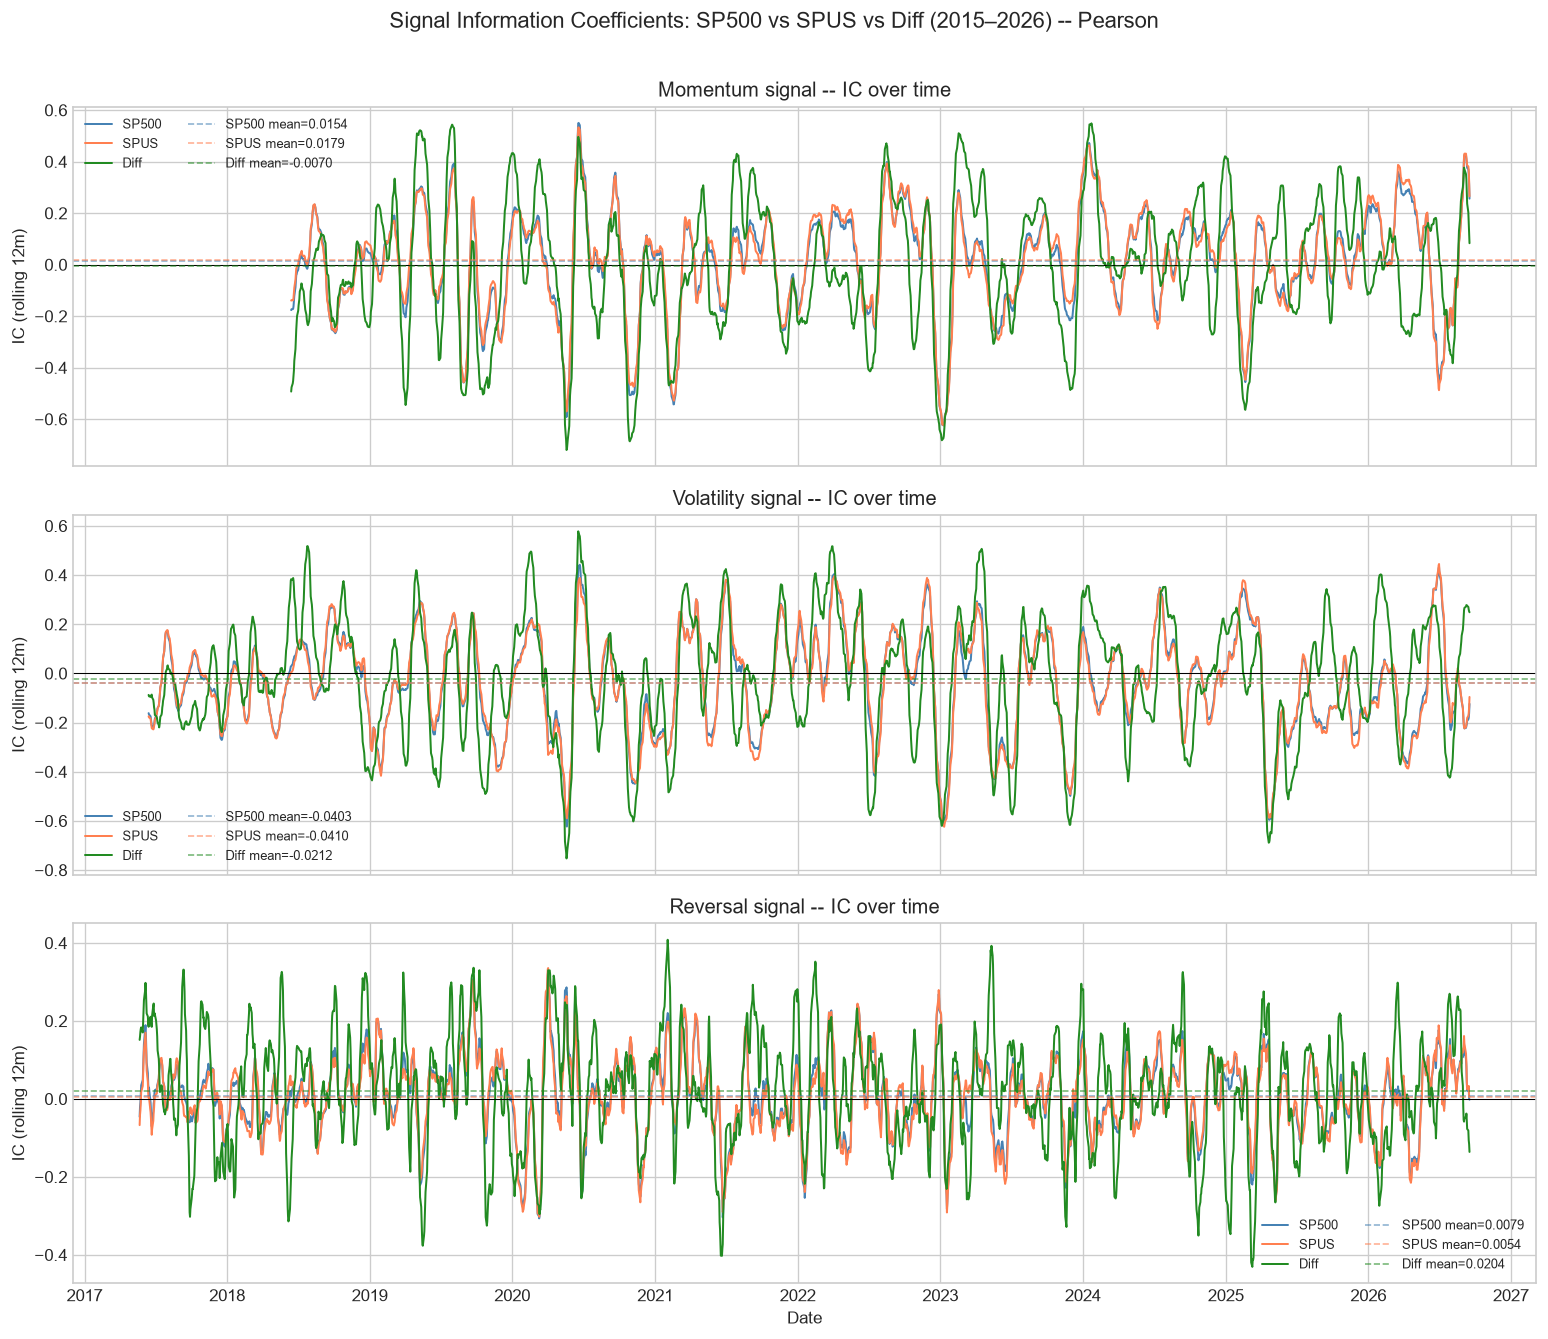

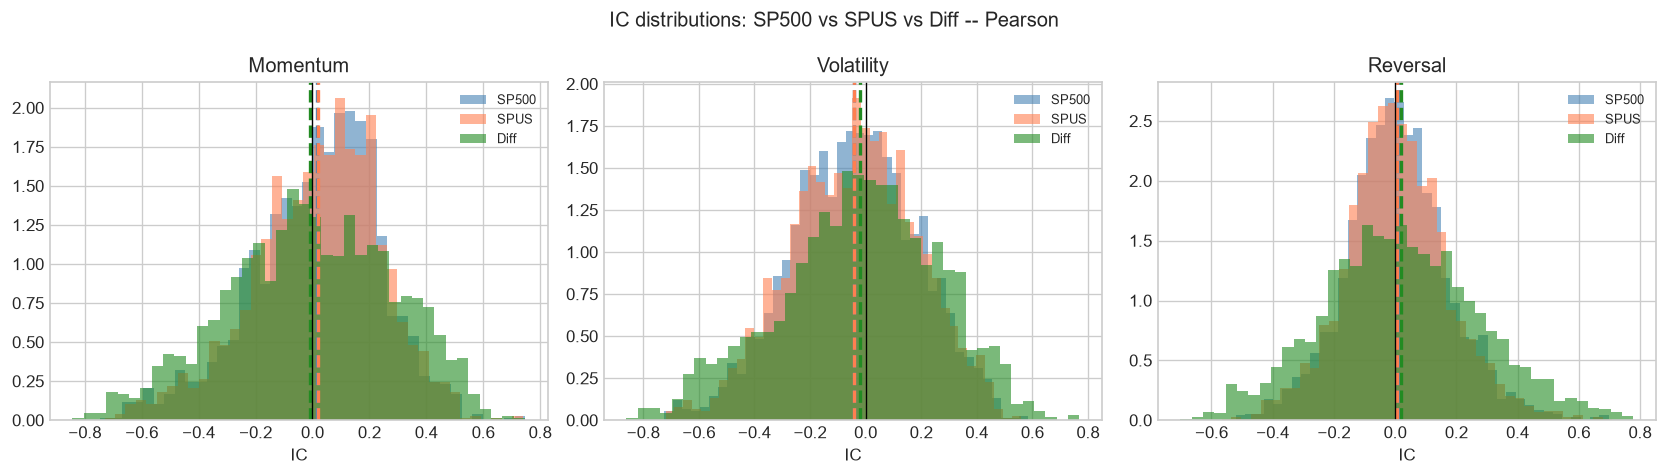

In [22]:

# ── Plot: rolling IC over time ────────────────────────────────────────────────

fig, axes = plt.subplots(3, 1, figsize=(13, 11), sharex=True)
window = 12  # 12-month rolling mean

for ax, sig_name, (ic_s, ic_u, ic_t) in zip(axes, signals.keys(), signals.values()):
    # Align series
    ic_s_roll = ic_s.rolling(window).mean()
    ic_u_roll = ic_u.rolling(window).mean()
    ic_t_roll = ic_t.rolling(window).mean()

    ax.plot(ic_s_roll, color='steelblue', lw=1.2, label='SP500')
    ax.plot(ic_u_roll, color='coral',     lw=1.2, label='SPUS')
    ax.plot(ic_t_roll, color='forestgreen',     lw=1.2, label='Diff')
    ax.axhline(0,              color='black', lw=0.6)
    ax.axhline(ic_s.mean(),   color='steelblue', ls='--', lw=1, alpha=0.6,
               label=f'SP500 mean={ic_s.mean():.4f}')
    ax.axhline(ic_u.mean(),   color='coral',     ls='--', lw=1, alpha=0.6,
               label=f'SPUS mean={ic_u.mean():.4f}')
    ax.axhline(ic_t.mean(),   color='forestgreen',     ls='--', lw=1, alpha=0.6,
               label=f'Diff mean={ic_t.mean():.4f}')

    # Shade periods where IC is negative (signal not working)
    #combined = ic_s_roll.reindex(ic_u_roll.index.union(ic_s_roll.index))
    #ax.fill_between(ic_s_roll.index, ic_s_roll, 0,
    #                where=ic_s_roll < 0,
    #                alpha=0.15, color='red', label='SP500 IC < 0')

    ax.set_ylabel('IC (rolling 12m)')
    ax.set_title(f'{sig_name} signal -- IC over time')
    ax.legend(fontsize=8, ncol=2)
    #ax.set_ylim(-0.15, 0.15)

axes[-1].set_xlabel('Date')
plt.suptitle('Signal Information Coefficients: SP500 vs SPUS vs Diff (2015–2026) -- Pearson',
             y=1.01, fontsize=13)
plt.tight_layout()
plt.show()


# ── IC distribution comparison ────────────────────────────────────────────────

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, sig_name, (ic_s, ic_u, ic_t) in zip(axes, signals.keys(), signals.values()):
    ax.hist(ic_s, bins=40, alpha=0.6, color='steelblue',
            density=True, label='SP500')
    ax.hist(ic_u, bins=40, alpha=0.6, color='coral',
            density=True, label='SPUS')
    ax.hist(ic_t, bins=40, alpha=0.6, color='forestgreen',
            density=True, label='Diff')
    ax.axvline(ic_s.mean(), color='steelblue', ls='--', lw=2)
    ax.axvline(ic_u.mean(), color='coral',     ls='--', lw=2)
    ax.axvline(ic_t.mean(), color='forestgreen',     ls='--', lw=2)
    ax.axvline(0, color='black', lw=0.8)
    ax.set_title(f'{sig_name}')
    ax.set_xlabel('IC')
    ax.legend(fontsize=8)

plt.suptitle('IC distributions: SP500 vs SPUS vs Diff -- Pearson', fontsize=12)
plt.tight_layout()
plt.show()

In [23]:
for sig_name, (ic_s, ic_u, ic_t) in zip(
    ['Momentum', 'Volatility', 'Reversal'],
    [(ic_mom_sp500, ic_mom_spus, ic_mom_diff),
     (ic_vol_sp500, ic_vol_spus, ic_vol_diff),
     (ic_rev_sp500, ic_rev_spus, ic_rev_diff)]
):
    common = ic_s.index.intersection(ic_u.index)
    t, p = scipy_stats.ttest_ind(ic_s[common], ic_u[common])
    print(f"{sig_name}: SP500 vs SPUS IC p-value = {p:.4f}")
    print()
    common = ic_u.index.intersection(ic_t.index)
    t, p = scipy_stats.ttest_ind(ic_u[common], ic_t[common])
    print(f"{sig_name}: SPUS vs Diff p-value = {p:.4f}")
    print()

Momentum: SP500 vs SPUS IC p-value = 0.7194

Momentum: SPUS vs Diff p-value = 0.0020

Volatility: SP500 vs SPUS IC p-value = 0.9177

Volatility: SPUS vs Diff p-value = 0.0089

Reversal: SP500 vs SPUS IC p-value = 0.6168

Reversal: SPUS vs Diff p-value = 0.0179



## Conclusion
We compare three equity universes over the 2015–2026 period: the full S&P 500 (470 stocks), a Sharia-screened subset (SPUS, 392 stocks after Stage 1 business activity exclusions), and the excluded companies (Diff, 78 stocks).

### Return and risk metrics

Mean annualised returns are $5.81\% \pm 8.97\%$ for SP500, $6.09\% \pm 9.31\%$ for SPUS, and $4.39\% \pm 6.84\%$ for the excluded companies. None of the pairwise differences are statistically significant (SPUS vs SP500 $p=0.65$, SPUS vs Diff $p=0.13$, SP500 vs Diff $p=0.19$), reflecting the large cross-sectional variance in individual stock returns over this period.

Mean Sharpe ratios are similar across all three groups (SP500: $0.35 \pm 0.23$, SPUS: $0.36 \pm 0.24$, Diff: $0.31 \pm 0.20$), with all values within one standard deviation of each other. Maximum drawdown is nearly identical across universes (approximately $-59\%$), indicating that Sharia screening provides no additional protection against market-wide tail risk events.

### Signal analysis

We evaluate three systematic signals — momentum, short-term reversal, and volatility — using both Spearman rank correlation and Pearson correlation between signal scores and 21-day forward returns.

**Momentum** shows no significant rank-predictive power in either universe under Spearman ($p=0.36$ for SP500, $p=0.29$ for SPUS), but exhibits significant magnitude predictability under Pearson ($p=0.002$ and $p=0.0003$). This divergence indicates a non-linear relationship between momentum and returns: extreme momentum stocks outperform meaningfully while the bulk of the ranking carries little signal. In the excluded universe, momentum is anti-predictive under Pearson (IC $= -0.007$), consistent with the mean-reverting nature of financial and real-estate stocks for which momentum is a structurally misaligned signal.

**Volatility** produces a significantly negative IC in both SP500 and SPUS under both methods (Spearman IC $\approx -0.034$, $p<0.001$; Pearson IC $\approx -0.040$, $p<0.001$), meaning high-volatility stocks outperform low-volatility stocks at the 21-day horizon. This is a horizon effect rather than a contradiction of the low-volatility anomaly: at short horizons in trending markets, high-volatility stocks generate larger absolute moves that are more often positive. The effect is weaker in the excluded universe (Pearson IC $= -0.021$), and SP500 and SPUS produce virtually identical values (comparison $p=0.999$). The difference between SPUS and Diff is statistically significant ($p=0.009$).

**Short-term reversal** is the most robust signal, exhibiting significant rank-predictive power across all three universes under Spearman (SP500: IC $=0.012$, $p=0.0004$; SPUS: IC $=0.011$, $p=0.001$; Diff: IC $=0.018$, $p=0.001$). Under Pearson, the reversal signal is notably stronger in the excluded universe (IC $=0.020$, $p<0.001$) compared to SP500 (IC $=0.008$, $p=0.023$) and SPUS (IC $=0.005$, $p=0.12$), with the SPUS vs Diff difference significant at $p=0.018$. This is consistent with the sharper, more predictable liquidity-driven price dislocations characteristic of financial stocks.

### Key finding

Across all three signals and both correlation methods, direct comparison of IC series between SP500 and SPUS yields $p$-values above $0.6$ in all cases (Spearman: momentum $p=0.93$, volatility $p=0.999$, reversal $p=0.79$; Pearson: momentum $p=0.72$, volatility $p=0.92$, reversal $p=0.62$). The signal predictive structure is statistically identical between the two universes. In contrast, the excluded universe exhibits significantly different signal behaviour under Pearson correlation (momentum $p=0.002$, volatility $p=0.009$, reversal $p=0.018$): momentum is anti-predictive, volatility effects are weaker, and short-term reversal is stronger — all consistent with the structural characteristics of excluded sectors.

Sharia screening removes a segment of the market whose return-generating structure is fundamentally different from the screened universe. Standard systematic signals — calibrated on the full S&P 500 — transfer cleanly to the Sharia-screened universe without recalibration, but are structurally misaligned with the excluded sectors. This provides a quantitative argument, independent of religious motivation, for why systematic strategies are better suited to Sharia-compliant universes than to the excluded segment.